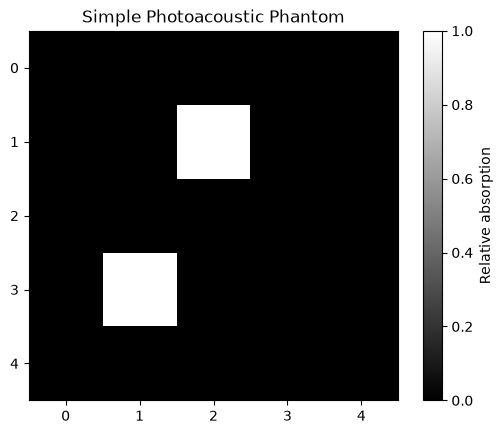

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Create a 5 by 5 phantom
phantom = np.zeros((5, 5))

# Add two absorbing points
phantom[1, 2] = 1
phantom[3, 1] = 1

# Display the phantom
plt.imshow(phantom, cmap="gray")
plt.colorbar(label="Relative absorption")
plt.title("Simple Photoacoustic Phantom")
plt.savefig("../outputs/day09_phantom.png", dpi=300, bbox_inches="tight")
plt.show()

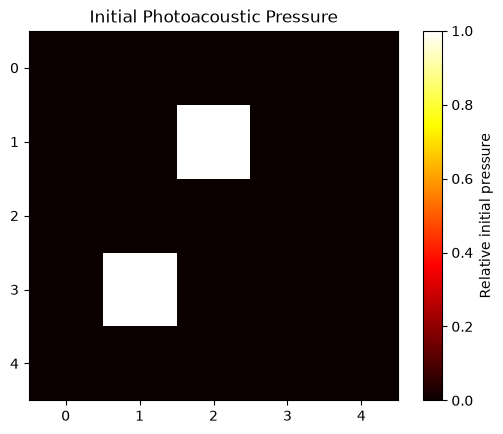

In [6]:
# Simplified initial pressure model

gamma = 1.0
fluence = 1.0

initial_pressure = gamma * phantom * fluence

plt.imshow(initial_pressure, cmap="hot")
plt.colorbar(label="Relative initial pressure")
plt.title("Initial Photoacoustic Pressure")
plt.savefig("../data/day09_initial_pressure.png",
            dpi=300, bbox_inches="tight")
plt.savefig("../outputs/day09_initial_pressure.png",
            dpi=300, bbox_inches="tight")
plt.show()

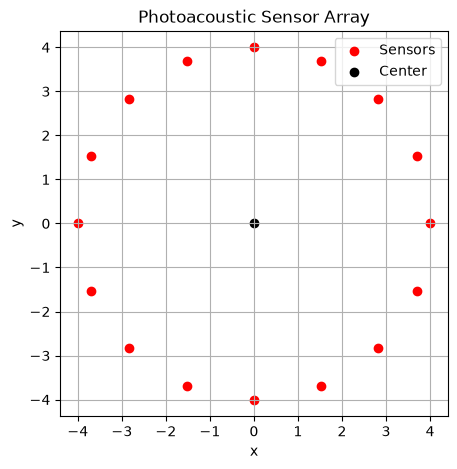

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Number of sensors
num_sensors = 16

# Sensor angles around the phantom
angles = np.linspace(0, 2 * np.pi, num_sensors, endpoint=False)

# Sensor positions
radius = 4
sensor_x = radius * np.cos(angles)
sensor_y = radius * np.sin(angles)

# Plot sensor positions
plt.figure(figsize=(5, 5))
plt.scatter(sensor_x, sensor_y, color="red", label="Sensors")
plt.scatter(0, 0, color="black", label="Center")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Photoacoustic Sensor Array")
plt.axis("equal")
plt.legend()
plt.grid(True)
plt.savefig("../outputs/day10_sensor_array.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Position of one source point
source_x = 0
source_y = 0

# Distance from source to each sensor
distances = np.sqrt(
    (sensor_x - source_x)**2 +
    (sensor_y - source_y)**2
)

print("Distances from source to sensors:")
print(distances)

Distances from source to sensors:
[4. 4. 4. 4. 4. 4. 4. 4. 4. 4. 4. 4. 4. 4. 4. 4.]


Arrival times (microseconds):
[26.66666667 26.66666667 26.66666667 26.66666667 26.66666667 26.66666667
 26.66666667 26.66666667 26.66666667 26.66666667 26.66666667 26.66666667
 26.66666667 26.66666667 26.66666667 26.66666667]


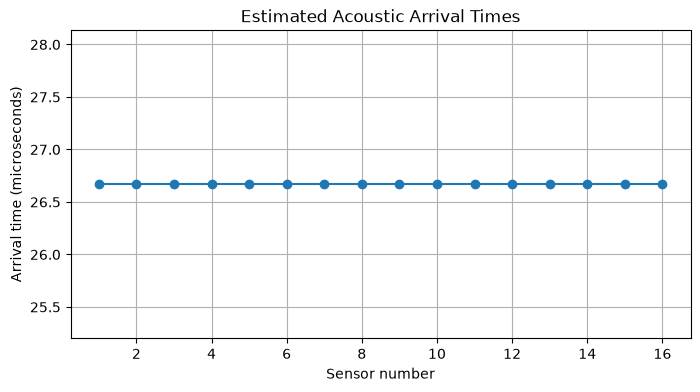

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Speed of sound in soft tissue (m/s)
sound_speed = 1500

# Convert distances from cm to meters
distances_m = distances / 100

# Calculate arrival times
arrival_times = distances_m / sound_speed

# Convert seconds to microseconds
arrival_times_us = arrival_times * 1e6

print("Arrival times (microseconds):")
print(arrival_times_us)

# Plot arrival times
plt.figure(figsize=(8, 4))
plt.plot(
    np.arange(1, len(arrival_times_us) + 1),
    arrival_times_us,
    "o-"
)

plt.xlabel("Sensor number")
plt.ylabel("Arrival time (microseconds)")
plt.title("Estimated Acoustic Arrival Times")
plt.grid(True)

plt.savefig("../outputs/day11_arrival_times.png",
            dpi=300, bbox_inches="tight")
plt.show()

Distances (cm):
[2.693 2.259 2.26  2.696 3.354 4.056 4.699 5.223 5.59  5.779 5.779 5.589
 5.22  4.696 4.052 3.35 ]

Arrival times (microseconds):
[17.951 15.058 15.067 17.971 22.361 27.04  31.325 34.817 37.268 38.527
 38.524 37.258 34.801 31.304 27.016 22.336]


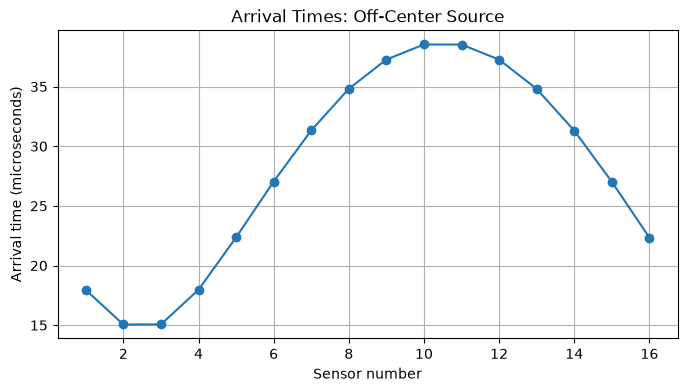

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Move the source away from the center (in cm)
source_x = 1.5
source_y = 1.0

# Calculate distances from the source to each sensor
distances_off_center = np.sqrt(
    (sensor_x - source_x)**2 +
    (sensor_y - source_y)**2
)

# Convert distances from cm to meters
distances_off_center_m = distances_off_center / 100

# Calculate arrival times in microseconds
arrival_times_off_center_us = (
    distances_off_center_m / sound_speed
) * 1e6
print("Distances (cm):")
print(np.round(distances_off_center, 3))

print("\nArrival times (microseconds):")
print(np.round(arrival_times_off_center_us, 3))

plt.figure(figsize=(8, 4))
plt.plot(
    np.arange(1, num_sensors + 1),
    arrival_times_off_center_us,
    "o-"
)

plt.xlabel("Sensor number")
plt.ylabel("Arrival time (microseconds)")
plt.title("Arrival Times: Off-Center Source")
plt.grid(True)

plt.savefig(
    "../outputs/day12_off_center_arrival_times.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#

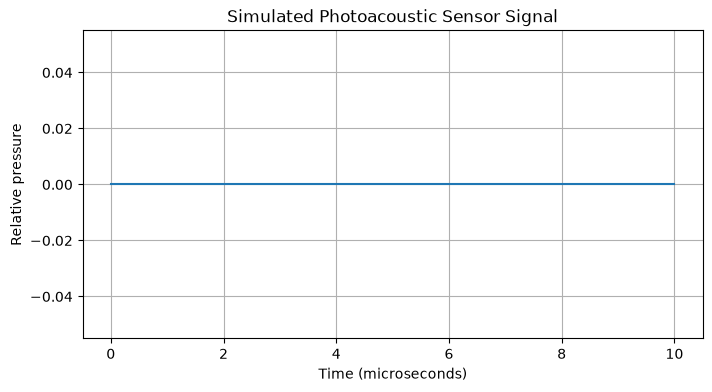

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Time axis in microseconds
time_us = np.linspace(0, 10, 1000)

# Select the first sensor's arrival time
arrival_time = arrival_times_off_center_us[0]

# Create a simple Gaussian-shaped acoustic pulse
pulse_width = 0.15

signal = np.exp(
    -((time_us - arrival_time) ** 2) /
    (2 * pulse_width ** 2)
)

# Plot the simulated sensor signal
plt.figure(figsize=(8, 4))
plt.plot(time_us, signal)

plt.xlabel("Time (microseconds)")
plt.ylabel("Relative pressure")
plt.title("Simulated Photoacoustic Sensor Signal")
plt.grid(True)

plt.savefig(
    "../outputs/day13_sensor_signal.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

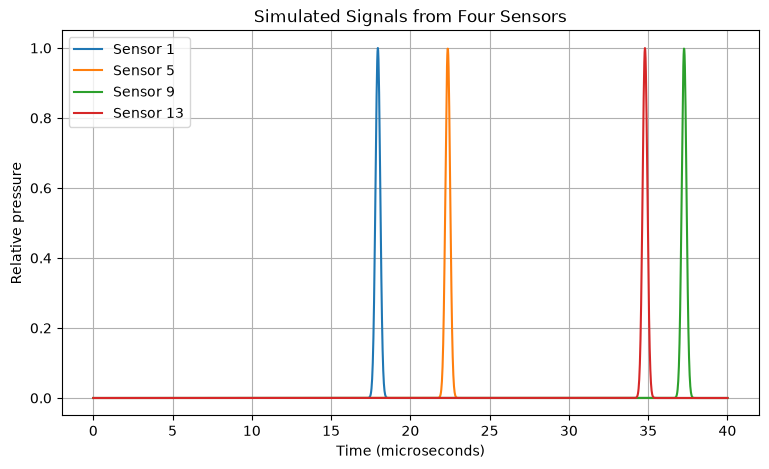

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# Time axis in microseconds
time_us = np.linspace(0, 40, 2000)

# Simulate signals from four sensors
pulse_width = 0.15
sensor_indices = [0, 4, 8, 12]

plt.figure(figsize=(9, 5))

for i in sensor_indices:
    arrival_time = arrival_times_off_center_us[i]

    signal = np.exp(
        -((time_us - arrival_time) ** 2) /
        (2 * pulse_width ** 2)
    )

    plt.plot(
        time_us,
        signal,
        label=f"Sensor {i + 1}"
    )

plt.xlabel("Time (microseconds)")
plt.ylabel("Relative pressure")
plt.title("Simulated Signals from Four Sensors")
plt.legend()
plt.grid(True)

plt.savefig(
    "../outputs/day14_four_sensor_signals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

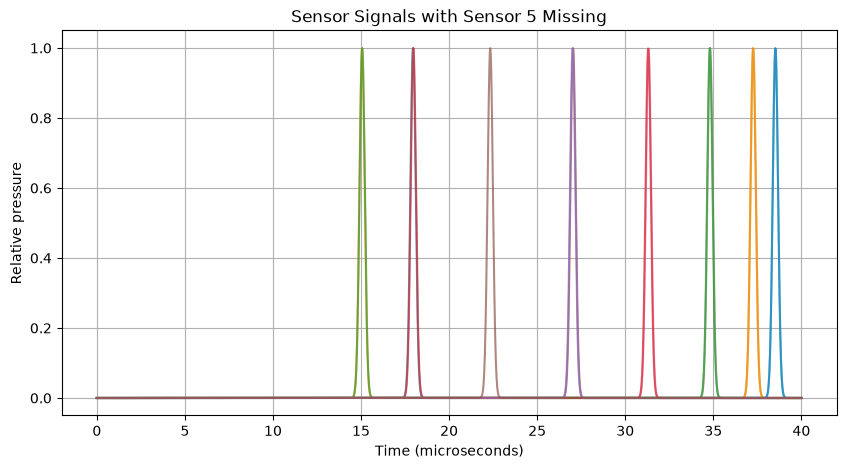

Signal matrix shape: (16, 2000)
Sensor 5 signal is missing: True


In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Time axis in microseconds
time_us = np.linspace(0, 40, 2000)

# Simulate signals from all 16 sensors
pulse_width = 0.15
all_signals = []

for arrival_time in arrival_times_off_center_us:
    signal = np.exp(
        -((time_us - arrival_time) ** 2) /
        (2 * pulse_width ** 2)
    )
    all_signals.append(signal)

all_signals = np.array(all_signals)

# Remove sensor 5's signal
missing_sensor = 4  # Python indexing starts from 0
signals_with_missing = all_signals.copy()
signals_with_missing[missing_sensor, :] = np.nan

# Plot all sensor signals
plt.figure(figsize=(10, 5))

for i in range(len(signals_with_missing)):
    plt.plot(
        time_us,
        signals_with_missing[i],
        alpha=0.7,
        label=f"Sensor {i + 1}"
    )

plt.xlabel("Time (microseconds)")
plt.ylabel("Relative pressure")
plt.title("Sensor Signals with Sensor 5 Missing")
plt.grid(True)

plt.savefig(
    "../outputs/day15_missing_sensor.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Signal matrix shape:", all_signals.shape)
print("Sensor 5 signal is missing:", np.all(np.isnan(
    signals_with_missing[missing_sensor]
)))

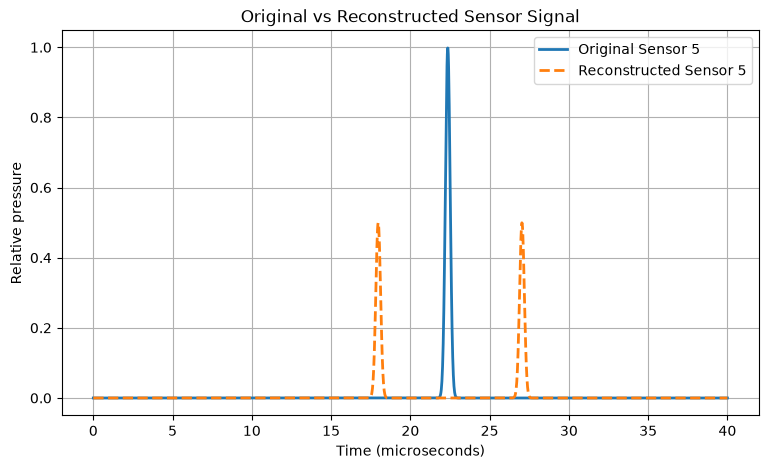

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# Sensor 5 is missing
missing_sensor = 4

# Copy the signals with the missing sensor
reconstructed_signals = signals_with_missing.copy()

# Neighboring sensors: 4 and 6
left_sensor = missing_sensor - 1
right_sensor = missing_sensor + 1

# Linear interpolation
reconstructed_signals[missing_sensor, :] = (
    signals_with_missing[left_sensor, :] +
    signals_with_missing[right_sensor, :]
) / 2

# Compare the original and reconstructed signals
plt.figure(figsize=(9, 5))

plt.plot(
    time_us,
    all_signals[missing_sensor],
    label="Original Sensor 5",
    linewidth=2
)

plt.plot(
    time_us,
    reconstructed_signals[missing_sensor],
    "--",
    label="Reconstructed Sensor 5",
    linewidth=2
)

plt.xlabel("Time (microseconds)")
plt.ylabel("Relative pressure")
plt.title("Original vs Reconstructed Sensor Signal")
plt.legend()
plt.grid(True)

plt.savefig(
    "../outputs/day16_reconstructed_sensor.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

MSE: 0.009965067884887858
RMSE: 0.0998251866258604


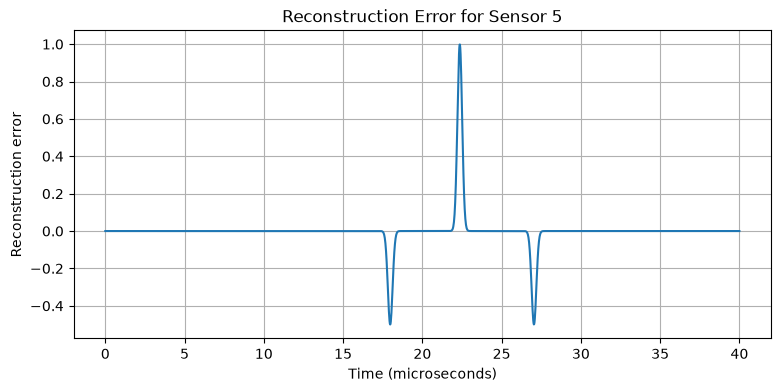

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Original and reconstructed signals for sensor 5
original = all_signals[4]
reconstructed = reconstructed_signals[4]

# Calculate reconstruction error
error = original - reconstructed

# Mean Squared Error (MSE)
mse = np.mean(error ** 2)

# Root Mean Squared Error (RMSE)
rmse = np.sqrt(mse)

print("MSE:", mse)
print("RMSE:", rmse)

# Plot the reconstruction error
plt.figure(figsize=(9, 4))
plt.plot(time_us, error)

plt.xlabel("Time (microseconds)")
plt.ylabel("Reconstruction error")
plt.title("Reconstruction Error for Sensor 5")
plt.grid(True)

plt.savefig(
    "../outputs/day17_reconstruction_error.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

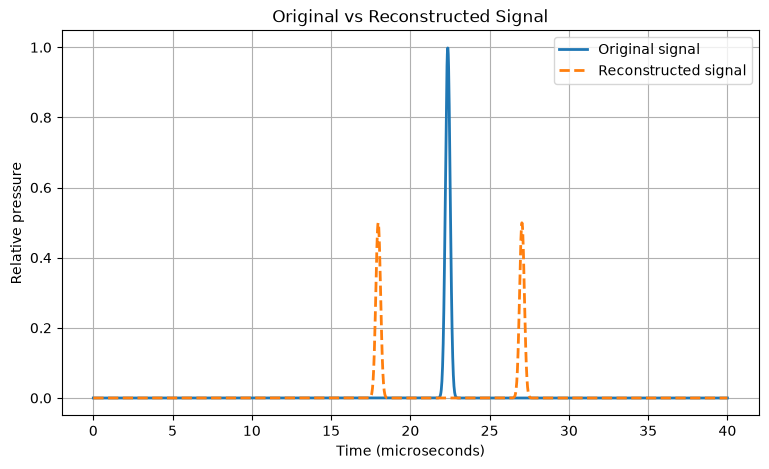

In [19]:
import numpy as np
import matplotlib.pyplot as plt

original = all_signals[4]
reconstructed = reconstructed_signals[4]

plt.figure(figsize=(9, 5))

plt.plot(
    time_us,
    original,
    label="Original signal",
    linewidth=2
)

plt.plot(
    time_us,
    reconstructed,
    "--",
    label="Reconstructed signal",
    linewidth=2
)

plt.xlabel("Time (microseconds)")
plt.ylabel("Relative pressure")
plt.title("Original vs Reconstructed Signal")
plt.legend()
plt.grid(True)

plt.savefig(
    "../outputs/day18_signal_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Estimated arrival time: 22.505656334041554 microseconds
Original arrival time: 22.360679774997898 microseconds
Linear reconstruction MSE: 0.0027672406061930626
Linear reconstruction RMSE: 0.05260456830155592


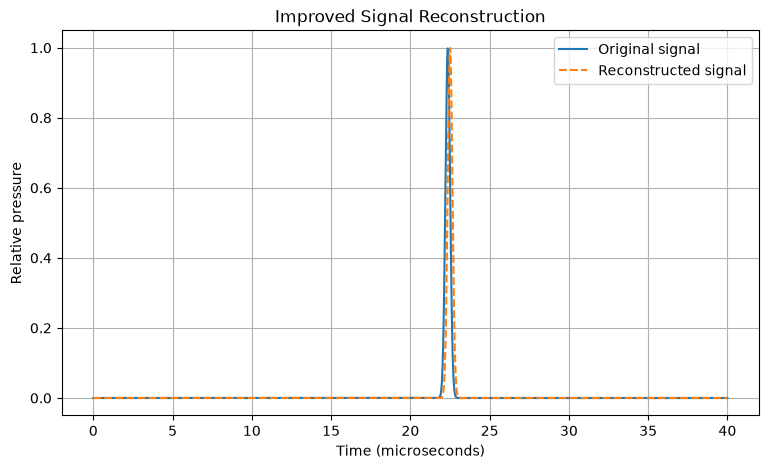

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# Sensor 5 is missing
missing_sensor = 4

# Neighboring sensors
left_sensor = 3
right_sensor = 5

# Estimate arrival time by linear interpolation
t_left = arrival_times_off_center_us[left_sensor]
t_right = arrival_times_off_center_us[right_sensor]

t_estimated = (t_left + t_right) / 2

# Reconstruct a Gaussian pulse at the estimated arrival time
pulse_width = 0.15

reconstructed_linear = np.exp(
    -((time_us - t_estimated) ** 2) /
    (2 * pulse_width ** 2)
)

original = all_signals[missing_sensor]

# Calculate errors
mse_linear = np.mean((original - reconstructed_linear) ** 2)
rmse_linear = np.sqrt(mse_linear)

print("Estimated arrival time:", t_estimated, "microseconds")
print("Original arrival time:",
      arrival_times_off_center_us[missing_sensor], "microseconds")
print("Linear reconstruction MSE:", mse_linear)
print("Linear reconstruction RMSE:", rmse_linear)

# Plot comparison
plt.figure(figsize=(9, 5))
plt.plot(time_us, original, label="Original signal")
plt.plot(time_us, reconstructed_linear, "--",
         label="Reconstructed signal")

plt.xlabel("Time (microseconds)")
plt.ylabel("Relative pressure")
plt.title("Improved Signal Reconstruction")
plt.legend()
plt.grid(True)

plt.savefig(
    "../outputs/day19_linear_reconstruction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

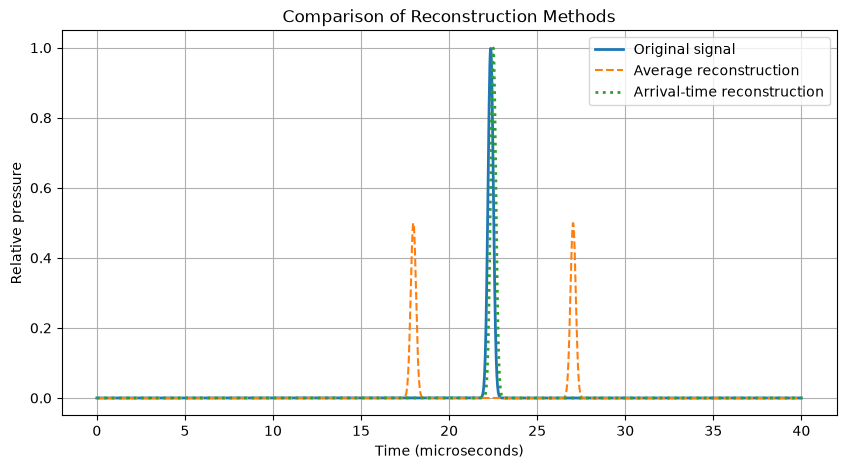

In [21]:
import numpy as np
import matplotlib.pyplot as plt

original = all_signals[4]
average_reconstruction = reconstructed_signals[4]

plt.figure(figsize=(10, 5))

plt.plot(
    time_us, original,
    label="Original signal",
    linewidth=2
)

plt.plot(
    time_us, average_reconstruction,
    "--",
    label="Average reconstruction"
)

plt.plot(
    time_us, reconstructed_linear,
    ":",
    label="Arrival-time reconstruction",
    linewidth=2
)

plt.xlabel("Time (microseconds)")
plt.ylabel("Relative pressure")
plt.title("Comparison of Reconstruction Methods")
plt.legend()
plt.grid(True)

plt.savefig(
    "../outputs/day20_reconstruction_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()